# SVM Classification: Legitimate vs Phishing URL
Notebook evaluasi SVM dengan Stratified 5-Fold Cross-Validation, CV Accuracy Mean ± SD, training model final, evaluasi test set, koefisien fitur, dan visualisasi.

**Sebelum menjalankan:** pastikan `train_features_17FIKS.csv` dan `test_features_17FIKS.csv` tersedia di direktori kerja Colab.

Train shape: (79998, 22)
Test shape : (38387, 22)

Jumlah fitur: 20
Jumlah sampel training: 79,998
Jumlah sampel test: 38,387

Distribusi kelas training:
ClassLabel
0    39999
1    39999
Name: count, dtype: int64

Distribusi kelas test:
ClassLabel
0    14658
1    23729
Name: count, dtype: int64

STRATIFIED 5-FOLD CROSS-VALIDATION — TRAINING SET


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CV Accuracy     : 0.96500 ± 0.00200
  Skor per fold : [0.96444 0.96375 0.96638 0.96769 0.96275]
CV Precision    : 0.96286 ± 0.00356
  Skor per fold : [0.96195 0.95836 0.96521 0.96751 0.96125]
CV Recall       : 0.96732 ± 0.00190
  Skor per fold : [0.96712 0.96962 0.96762 0.96788 0.96437]
CV F1-Score     : 0.96508 ± 0.00196
  Skor per fold : [0.96453 0.96396 0.96642 0.96769 0.96281]
CV ROC-AUC      : 0.99066 ± 0.00085
  Skor per fold : [0.99025 0.99075 0.99158 0.99128 0.98945]

Ringkasan untuk tabel laporan:
      Metric         Mean ± SD
 CV Accuracy 0.96500 ± 0.00200
CV Precision 0.96286 ± 0.00356
   CV Recall 0.96732 ± 0.00190
 CV F1-Score 0.96508 ± 0.00196
  CV ROC-AUC 0.99066 ± 0.00085

File CV tersimpan: svm_cv_fold_scores.csv dan svm_cv_mean_sd_summary.csv

TRAINING FINAL MODEL


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Waktu training: 6.44 detik


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



EVALUASI TEST SET INDEPENDEN
Test Accuracy: 0.9486 (94.86%)

Classification Report:
                      precision    recall  f1-score   support

Class 0 (Legitimate)     0.9504    0.9129    0.9313     14658
  Class 1 (Phishing)     0.9475    0.9706    0.9589     23729

            accuracy                         0.9486     38387
           macro avg     0.9489    0.9417    0.9451     38387
        weighted avg     0.9486    0.9486    0.9483     38387

Confusion Matrix (baris=actual, kolom=predicted; urutan kelas [0, 1]):
[[13381  1277]
 [  698 23031]]
Sensitivity/Recall kelas 1 (Phishing): 0.9706
Test ROC-AUC: 0.9814


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


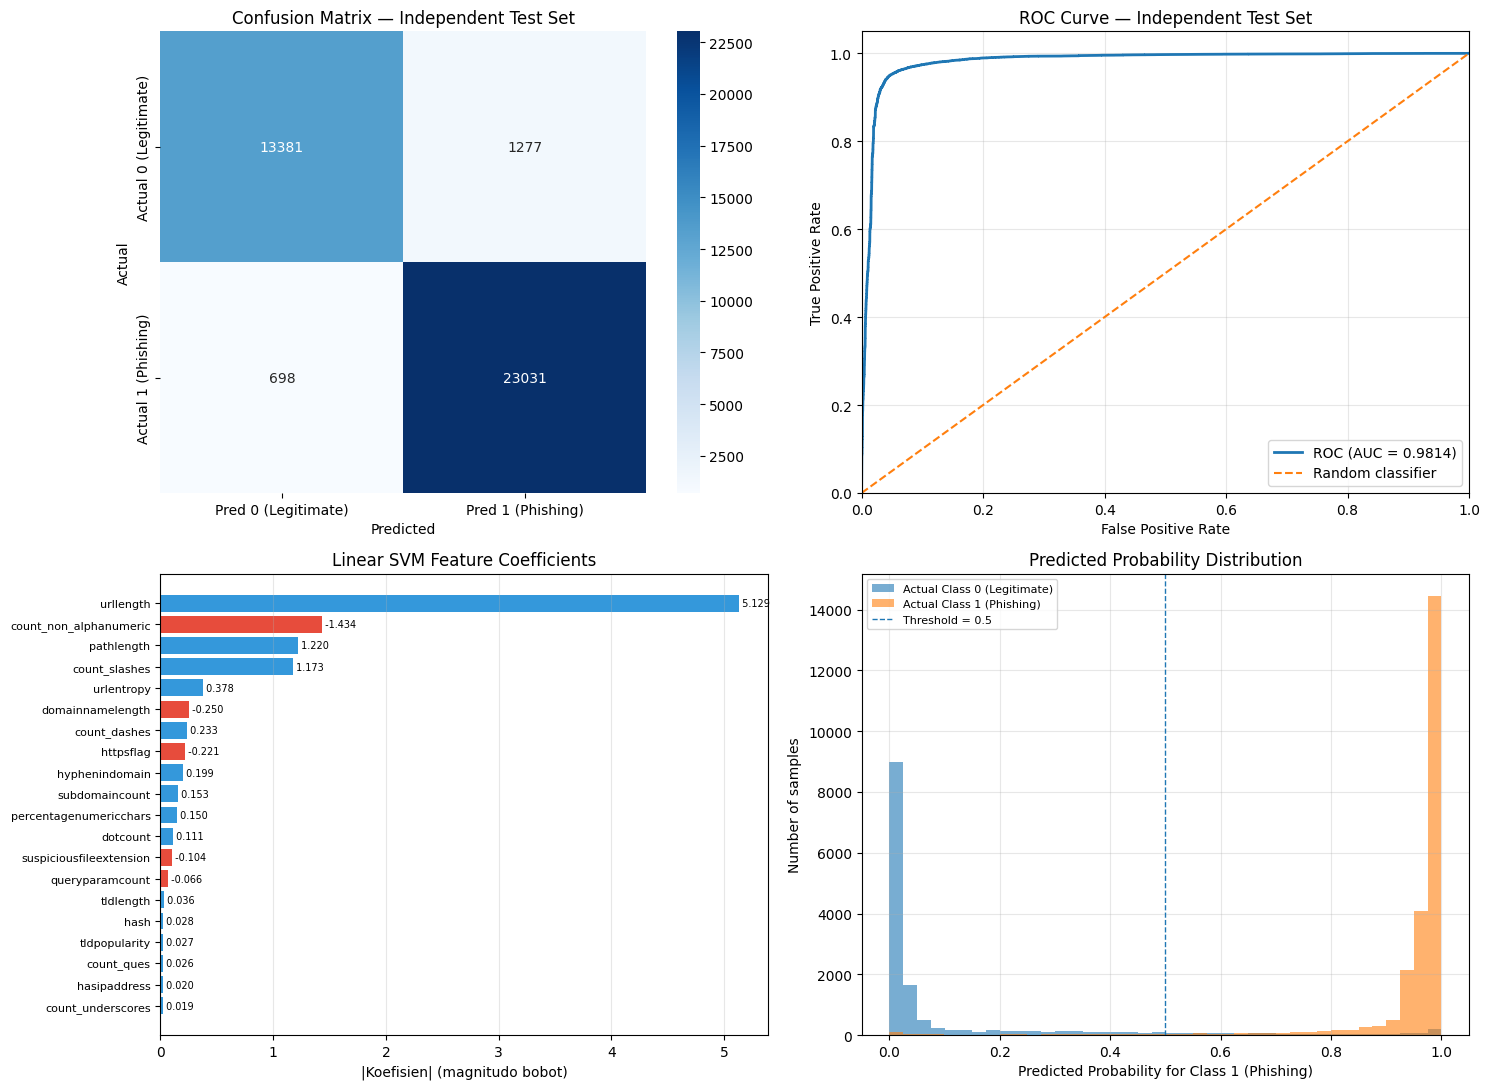


Koefisien fitur teratas:
               Feature  Coefficient  AbsoluteCoefficient
             urllength     5.128996             5.128996
count_non_alphanumeric    -1.433769             1.433769
            pathlength     1.220089             1.220089
         count_slashes     1.173163             1.173163
            urlentropy     0.377934             0.377934
      domainnamelength    -0.250129             0.250129
          count_dashes     0.232527             0.232527
             httpsflag    -0.220913             0.220913
        hyphenindomain     0.199384             0.199384
        subdomaincount     0.152737             0.152737

File tersimpan: svm_visualizations.png dan svm_feature_coefficients.csv

Membuat visualisasi decision boundary PCA 2D (opsional)...
Variance explained oleh 2 komponen PCA: 37.24%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

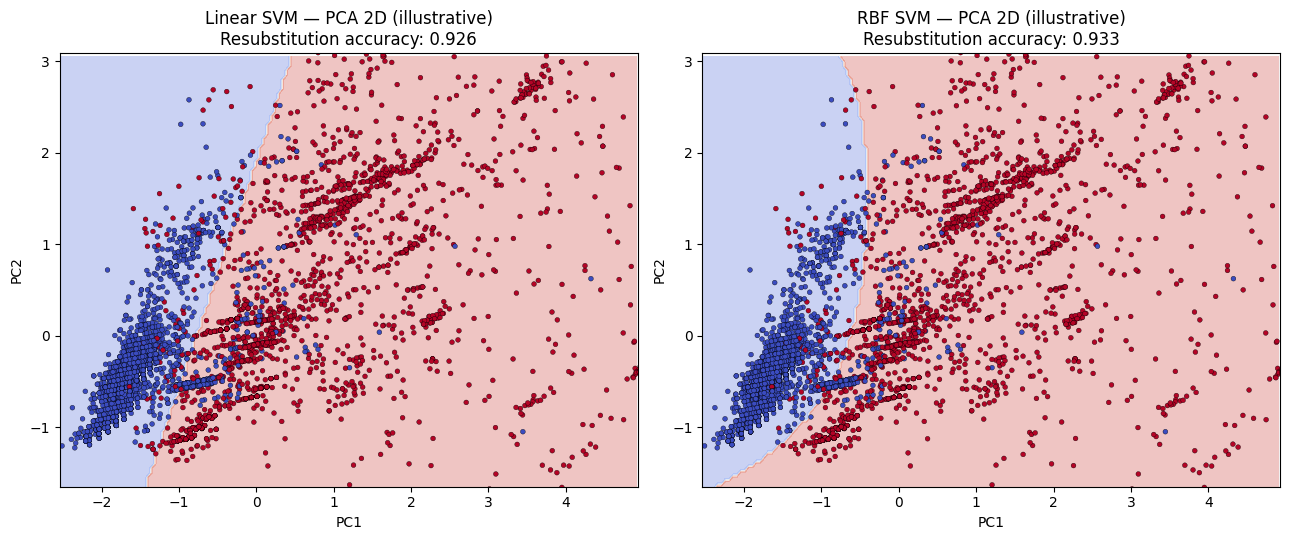


Selesai.


In [ ]:
# -*- coding: utf-8 -*-
"""
SVM Classification: Legitimate vs Phishing URL
Evaluasi:
1. Stratified 5-Fold Cross-Validation pada training set
2. Mean CV Accuracy +/- SD
3. Training model final dengan CalibratedClassifierCV
4. Evaluasi pada test set independen
5. Koefisien fitur Linear SVM
6. Visualisasi confusion matrix, ROC, feature coefficients,
   probability distribution, dan PCA decision boundary

Catatan:
- Pastikan nama file CSV sesuai dengan file yang diunggah ke Colab.
- Kolom target: ClassLabel
- Kolom URL (jika ada): url
- Semua fitur yang digunakan harus numerik.
"""

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    recall_score,
    roc_curve,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC

warnings.filterwarnings("default")

# ============================================================
# 1. LOAD DATA
# ============================================================
TRAIN_PATH = "features_24_hybrid_20.csv"
TEST_PATH = "testing_features_24_hybrid_20.csv"
RANDOM_STATE = 42

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

print("Train shape:", train.shape)
print("Test shape :", test.shape)

TARGET = "ClassLabel"
URL_COLUMN_CANDIDATES = ["url", "URL"]

if TARGET not in train.columns or TARGET not in test.columns:
    raise ValueError(f"Kolom target '{TARGET}' harus tersedia di train dan test.")

# Gunakan kolom yang tersedia pada kedua dataset; jangan gunakan URL sebagai fitur.
excluded_cols = [TARGET] + [
    c for c in URL_COLUMN_CANDIDATES if c in train.columns
]
feature_cols = [c for c in train.columns if c not in excluded_cols]

missing_test_cols = [c for c in feature_cols if c not in test.columns]
if missing_test_cols:
    raise ValueError(
        "Kolom fitur berikut tidak ditemukan di test set: "
        + ", ".join(missing_test_cols)
    )

X_train = train[feature_cols].copy()
y_train = train[TARGET].astype(int).copy()
X_test = test[feature_cols].copy()
y_test = test[TARGET].astype(int).copy()

# Pastikan fitur numerik dan tidak ada nilai hilang/infinite.
# Jika ada, berhenti agar data dapat diperiksa, bukan diam-diam diubah.
for label, frame in [("training", X_train), ("test", X_test)]:
    non_numeric = frame.select_dtypes(exclude=[np.number]).columns.tolist()
    if non_numeric:
        raise ValueError(
            f"Ada fitur non-numerik di data {label}: {non_numeric}. "
            "Hapus/encode fitur tersebut terlebih dahulu."
        )
    if frame.isna().any().any():
        cols = frame.columns[frame.isna().any()].tolist()
        raise ValueError(
            f"Ada missing values di data {label}, kolom: {cols}. "
            "Tangani missing values hanya dengan prosedur yang sesuai."
        )
    if not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError(f"Ada nilai infinite di data {label}.")

# Samakan urutan kolom test dengan training.
X_test = X_test[feature_cols]

print(f"\nJumlah fitur: {len(feature_cols)}")
print(f"Jumlah sampel training: {len(X_train):,}")
print(f"Jumlah sampel test: {len(X_test):,}")
print("\nDistribusi kelas training:")
print(y_train.value_counts().sort_index())
print("\nDistribusi kelas test:")
print(y_test.value_counts().sort_index())

# ============================================================
# 2. STRATIFIED 5-FOLD CV — TRAINING SET SAJA
#    Semua metrik dilaporkan sebagai Mean +/- SD.
#    Pipeline mencegah data leakage dari StandardScaler.
# ============================================================
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        C=1.0,
        random_state=RANDOM_STATE,
        max_iter=5000,
        dual=False,
    )),
])

print("\n" + "=" * 70)
print("STRATIFIED 5-FOLD CROSS-VALIDATION — TRAINING SET")
print("=" * 70)

# ClassLabel diasumsikan: 0 = Legitimate, 1 = Phishing.
# ROC-AUC menggunakan decision_function dari LinearSVC.
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv_results = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False,
)

metric_labels = {
    "accuracy": "CV Accuracy",
    "precision": "CV Precision",
    "recall": "CV Recall",
    "f1": "CV F1-Score",
    "roc_auc": "CV ROC-AUC",
}

summary_rows = []
for metric, label in metric_labels.items():
    fold_scores = cv_results[f"test_{metric}"]
    mean_score = fold_scores.mean()
    sd_score = fold_scores.std(ddof=1)
    summary_rows.append({
        "Metric": label,
        "Mean": mean_score,
        "SD": sd_score,
        "Mean ± SD": f"{mean_score:.5f} ± {sd_score:.5f}",
    })
    print(f"{label:16s}: {mean_score:.5f} ± {sd_score:.5f}")
    print("  Skor per fold :", np.round(fold_scores, 5))

cv_summary = pd.DataFrame(summary_rows)
print("\nRingkasan untuk tabel laporan:")
print(cv_summary[["Metric", "Mean ± SD"]].to_string(index=False))

# Simpan ringkasan dan skor per fold untuk dokumentasi.
fold_summary = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1_Score": cv_results["test_f1"],
    "ROC_AUC": cv_results["test_roc_auc"],
})
fold_summary.to_csv("svm_cv_fold_scores.csv", index=False)
cv_summary.to_csv("svm_cv_mean_sd_summary.csv", index=False)
print("\nFile CV tersimpan: svm_cv_fold_scores.csv dan svm_cv_mean_sd_summary.csv")

# ============================================================
# 3. TRAIN FINAL CALIBRATED MODEL
#    Calibration CV juga memakai pipeline, jadi scaler di-fit
#    hanya pada bagian training dari tiap calibration fold.
# ============================================================
print("\n" + "=" * 60)
print("TRAINING FINAL MODEL")
print("=" * 60)

start_time = time.time()

# Kompatibel dengan versi sklearn baru dan versi yang lebih lama.
try:
    calibrated_svm = CalibratedClassifierCV(
        estimator=clone(svm_pipeline),
        method="sigmoid",
        cv=3,
    )
except TypeError:
    calibrated_svm = CalibratedClassifierCV(
        base_estimator=clone(svm_pipeline),
        method="sigmoid",
        cv=3,
    )

calibrated_svm.fit(X_train, y_train)
print(f"Waktu training: {time.time() - start_time:.2f} detik")

# Model LinearSVC terpisah untuk koefisien fitur.
# Fit scaler dan SVM pada seluruh training set.
coef_pipeline = clone(svm_pipeline)
coef_pipeline.fit(X_train, y_train)
coef_model = coef_pipeline.named_steps["svm"]

# ============================================================
# 4. FINAL EVALUATION — INDEPENDENT TEST SET
# ============================================================
print("\n" + "=" * 60)
print("EVALUASI TEST SET INDEPENDEN")
print("=" * 60)

y_pred = calibrated_svm.predict(X_test)
y_proba = calibrated_svm.predict_proba(X_test)[:, 1]

test_accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
sensitivity = recall_score(y_test, y_pred, pos_label=1)
fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=1)
test_auc = auc(fpr, tpr)

print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Class 0 (Legitimate)", "Class 1 (Phishing)"],
    digits=4,
    zero_division=0,
))
print("Confusion Matrix (baris=actual, kolom=predicted; urutan kelas [0, 1]):")
print(cm)
print(f"Sensitivity/Recall kelas 1 (Phishing): {sensitivity:.4f}")
print(f"Test ROC-AUC: {test_auc:.4f}")

# ============================================================
# 5. VISUALIZATION: CONFUSION MATRIX, ROC, COEFFICIENTS,
#    PROBABILITY DISTRIBUTION
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Confusion matrix: label harus konsisten dengan ClassLabel 0/1.
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0, 0],
    xticklabels=["Pred 0 (Legitimate)", "Pred 1 (Phishing)"],
    yticklabels=["Actual 0 (Legitimate)", "Actual 1 (Phishing)"],
)
axes[0, 0].set_title("Confusion Matrix — Independent Test Set")
axes[0, 0].set_xlabel("Predicted")
axes[0, 0].set_ylabel("Actual")

# ROC
axes[0, 1].plot(fpr, tpr, lw=2, label=f"ROC (AUC = {test_auc:.4f})")
axes[0, 1].plot([0, 1], [0, 1], linestyle="--", lw=1.5, label="Random classifier")
axes[0, 1].set_xlim(0, 1)
axes[0, 1].set_ylim(0, 1.05)
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].set_title("ROC Curve — Independent Test Set")
axes[0, 1].legend(loc="lower right")
axes[0, 1].grid(alpha=0.3)

# Feature coefficients. Coefficient sign reflects direction toward class 1
# under the binary LinearSVC convention; absolute value gives magnitude.
coef = coef_model.coef_[0]
importance = np.abs(coef)
order = np.argsort(importance)
feature_arr = np.array(feature_cols)
bar_colors = ["#e74c3c" if coef[i] < 0 else "#3498db" for i in order]

bars = axes[1, 0].barh(
    np.arange(len(order)),
    importance[order],
    color=bar_colors,
)
axes[1, 0].set_yticks(np.arange(len(order)))
axes[1, 0].set_yticklabels(feature_arr[order], fontsize=8)
axes[1, 0].set_xlabel("|Koefisien| (magnitudo bobot)")
axes[1, 0].set_title("Linear SVM Feature Coefficients")
axes[1, 0].grid(alpha=0.3, axis="x")

# Label nilai koefisien asli, bukan nilai absolut.
for bar, feature_idx in zip(bars, order):
    axes[1, 0].text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {coef[feature_idx]:.3f}",
        va="center",
        fontsize=7,
    )

# Probability distributions: positive class is ClassLabel=1 (Phishing).
axes[1, 1].hist(
    y_proba[y_test.to_numpy() == 0],
    bins=40,
    alpha=0.6,
    label="Actual Class 0 (Legitimate)",
)
axes[1, 1].hist(
    y_proba[y_test.to_numpy() == 1],
    bins=40,
    alpha=0.6,
    label="Actual Class 1 (Phishing)",
)
axes[1, 1].axvline(0.5, linestyle="--", linewidth=1, label="Threshold = 0.5")
axes[1, 1].set_xlabel("Predicted Probability for Class 1 (Phishing)")
axes[1, 1].set_ylabel("Number of samples")
axes[1, 1].set_title("Predicted Probability Distribution")
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("svm_visualizations.png", dpi=150, bbox_inches="tight")
plt.show()

# Simpan tabel koefisien agar bisa diperiksa/diurutkan.
coef_table = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": coef,
    "AbsoluteCoefficient": np.abs(coef),
}).sort_values("AbsoluteCoefficient", ascending=False)

coef_table.to_csv("svm_feature_coefficients.csv", index=False)
print("\nKoefisien fitur teratas:")
print(coef_table.head(10).to_string(index=False))
print("\nFile tersimpan: svm_visualizations.png dan svm_feature_coefficients.csv")

# ============================================================
# 6. OPTIONAL: DECISION BOUNDARY PADA PROYEKSI PCA 2D
#    Ini hanya ilustrasi di ruang 2D, bukan evaluasi final.
# ============================================================
print("\nMembuat visualisasi decision boundary PCA 2D (opsional)...")

X_train_scaled_full = coef_pipeline.named_steps["scaler"].transform(X_train)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_scaled_full)

print(
    "Variance explained oleh 2 komponen PCA: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

rng = np.random.default_rng(RANDOM_STATE)
sample_size = min(5000, len(X_train_2d))
sample_idx = rng.choice(len(X_train_2d), size=sample_size, replace=False)
X_sample = X_train_2d[sample_idx]
y_sample = y_train.to_numpy()[sample_idx]

# Model-model ini hanya untuk plot pada data 2D subsample.
svm_linear_2d = SVC(kernel="linear", C=1.0, random_state=RANDOM_STATE)
svm_rbf_2d = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)
svm_linear_2d.fit(X_sample, y_sample)
svm_rbf_2d.fit(X_sample, y_sample)

def plot_decision_boundary(ax, model, X, y, title):
    # Gunakan rentang persentil agar plot tidak terlalu dipengaruhi outlier.
    x_min_data, x_max_data = np.percentile(X[:, 0], [5, 95])
    y_min_data, y_max_data = np.percentile(X[:, 1], [5, 95])

    x_pad = max((x_max_data - x_min_data) * 0.1, 0.5)
    y_pad = max((y_max_data - y_min_data) * 0.1, 0.5)
    x_min, x_max = x_min_data - x_pad, x_max_data + x_pad
    y_min, y_max = y_min_data - y_pad, y_max_data + y_pad

    h = 0.05
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, h),
        np.arange(y_min, y_max, h),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm",
               edgecolors="k", s=12, linewidths=0.25)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_decision_boundary(
    axes[0],
    svm_linear_2d,
    X_sample,
    y_sample,
    f"Linear SVM — PCA 2D (illustrative)\n"
    f"Resubstitution accuracy: {svm_linear_2d.score(X_sample, y_sample):.3f}",
)
plot_decision_boundary(
    axes[1],
    svm_rbf_2d,
    X_sample,
    y_sample,
    f"RBF SVM — PCA 2D (illustrative)\n"
    f"Resubstitution accuracy: {svm_rbf_2d.score(X_sample, y_sample):.3f}",
)
plt.tight_layout()
plt.savefig("svm_pca_decision_boundary.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nSelesai.")